In [10]:
import pandas as pd, numpy as np, json
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

sales = pd.read_csv("../data/clean/cleaned_sales.csv", dtype={"InvoiceNo": str},
                    parse_dates=["InvoiceDate"])
sales = sales.dropna(subset=["CustomerID"]).copy()     # guest checkouts have no ID
sales["CustomerID"] = sales["CustomerID"].astype(int).astype(str)
sales["OrderMonth"] = sales["InvoiceDate"].dt.to_period("M")
print(sales.shape, sales["CustomerID"].nunique(), "customers")

(392692, 14) 4338 customers


In [11]:
snapshot = sales["InvoiceDate"].max() + pd.Timedelta(days=1)   # "today" for this dataset

orders = (sales.groupby(["CustomerID", "InvoiceNo"])
               .agg(order_date=("InvoiceDate", "min"), order_value=("Revenue", "sum"))
               .reset_index())

cust = orders.groupby("CustomerID").agg(
    first_order=("order_date", "min"),
    last_order=("order_date", "max"),
    orders=("InvoiceNo", "nunique"),
    total_spend=("order_value", "sum"),
    avg_order_value=("order_value", "mean"),
)
cust["recency_days"] = (snapshot - cust["last_order"]).dt.days
cust["lifetime_days"] = (cust["last_order"] - cust["first_order"]).dt.days
cust["is_repeat"] = (cust["orders"] > 1).astype(int)
cust["churned"] = (cust["recency_days"] > 90).astype(int)   # no order in the last 90 days
cust = cust.reset_index()
cust.to_csv("../data/clean/customers.csv", index=False)
cust.head()

,CustomerID,first_order,last_order,orders,total_spend,avg_order_value,recency_days,lifetime_days,is_repeat,churned
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,77183.600000,326,0,0,1
1,12347,2010-12-07 14:57:00,2011-12-07 15:52:00,7,4310.00,615.714286,2,365,1,0
2,12348,2010-12-16 19:09:00,2011-09-25 13:13:00,4,1797.24,449.310000,75,282,1,0
3,12349,2011-11-21 09:51:00,2011-11-21 09:51:00,1,1757.55,1757.550000,19,0,0,0
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,334.400000,310,0,0,1


In [12]:
n = len(cust)
repeat_rate = cust["is_repeat"].mean()
print(f"Customers: {n:,} | Repeat rate: {repeat_rate:.1%} | Churn rate (90d): {cust['churned'].mean():.1%}")
print(f"Avg orders/customer: {cust['orders'].mean():.2f} | Avg spend/customer: {cust['total_spend'].mean():,.2f}")

# Top 20% of customers: how much revenue do they bring?
top20 = cust.nlargest(int(n*0.2), "total_spend")["total_spend"].sum() / cust["total_spend"].sum()
print(f"Top 20% of customers = {top20:.1%} of revenue")

Customers: 4,338 | Repeat rate: 65.6% | Churn rate (90d): 33.4%
Avg orders/customer: 4.27 | Avg spend/customer: 2,048.69
Top 20% of customers = 74.7% of revenue


In [13]:
def iqr_report(s, name):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    out = s[(s < lo) | (s > hi)]
    print(f"{name}: mean={s.mean():,.2f} median={s.median():,.2f} std={s.std():,.2f} "
          f"skew={s.skew():.2f} IQR={iqr:,.2f} outliers={len(out)} ({len(out)/len(s):.1%})")
    return hi

spend_hi  = iqr_report(cust["total_spend"], "Total spend")
orders_hi = iqr_report(cust["orders"], "Orders per customer")
rec_hi    = iqr_report(cust["recency_days"], "Recency (days)")

Total spend: mean=2,048.69 median=668.57 std=8,985.23 skew=19.34 IQR=1,354.12 outliers=425 (9.8%)
Orders per customer: mean=4.27 median=2.00 std=7.70 skew=12.07 IQR=4.00 outliers=285 (6.6%)
Recency (days): mean=92.54 median=51.00 std=100.01 skew=1.25 IQR=124.00 outliers=155 (3.6%)


In [14]:
cust["R"] = pd.qcut(cust["recency_days"], 4, labels=[4,3,2,1]).astype(int)
cust["F"] = pd.qcut(cust["orders"].rank(method="first"), 4, labels=[1,2,3,4]).astype(int)
cust["M"] = pd.qcut(cust["total_spend"], 4, labels=[1,2,3,4]).astype(int)
cust["RFM"] = cust["R"] + cust["F"] + cust["M"]

def segment(s):
    if s >= 10: return "Champions"
    if s >= 8:  return "Loyal"
    if s >= 6:  return "Potential"
    if s >= 4:  return "At risk"
    return "Lost"
cust["segment"] = cust["RFM"].apply(segment)
cust.to_csv("../data/clean/customers.csv", index=False)     # save again with segments
print(cust.groupby("segment").agg(customers=("CustomerID","count"),
      avg_spend=("total_spend","mean"), avg_orders=("orders","mean")).round(1))

           customers  avg_spend  avg_orders
segment                                    
At risk          991      312.3         1.2
Champions       1267     5388.5         9.9
Lost             300      161.2         1.0
Loyal            845     1244.5         3.2
Potential        935      695.8         1.9


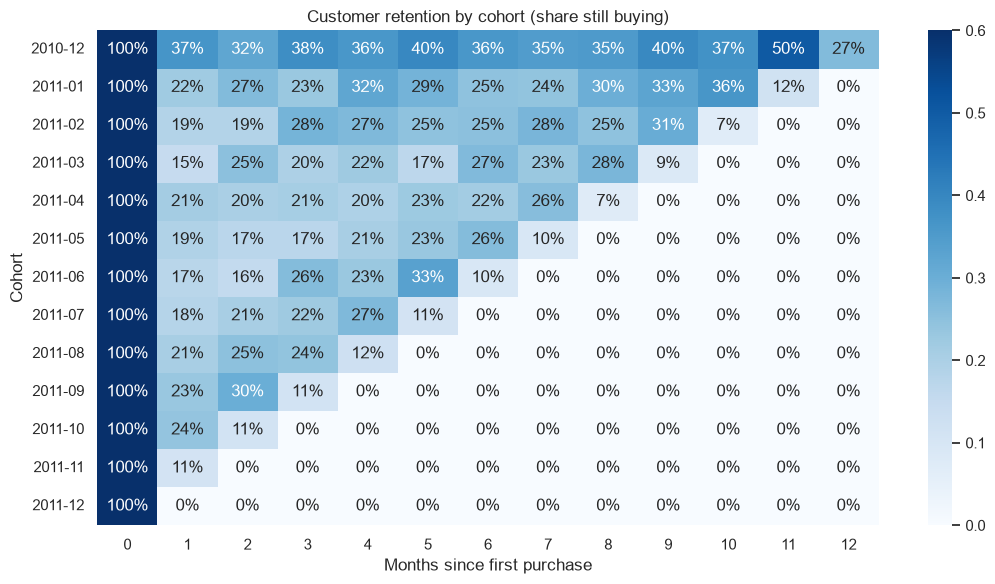

In [15]:
sales["CohortMonth"] = sales.groupby("CustomerID")["InvoiceDate"].transform("min").dt.to_period("M")
sales["Period"] = (sales["OrderMonth"] - sales["CohortMonth"]).apply(lambda x: x.n)

cohort = (sales.groupby(["CohortMonth", "Period"])["CustomerID"].nunique()
               .unstack(fill_value=0))
retention = cohort.divide(cohort[0], axis=0)

plt.figure(figsize=(11, 6))
sns.heatmap(retention, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=0.6)
plt.title("Customer retention by cohort (share still buying)")
plt.xlabel("Months since first purchase"); plt.ylabel("Cohort")
plt.tight_layout(); plt.savefig("../site/images/cohort_retention.png", dpi=150); plt.show()

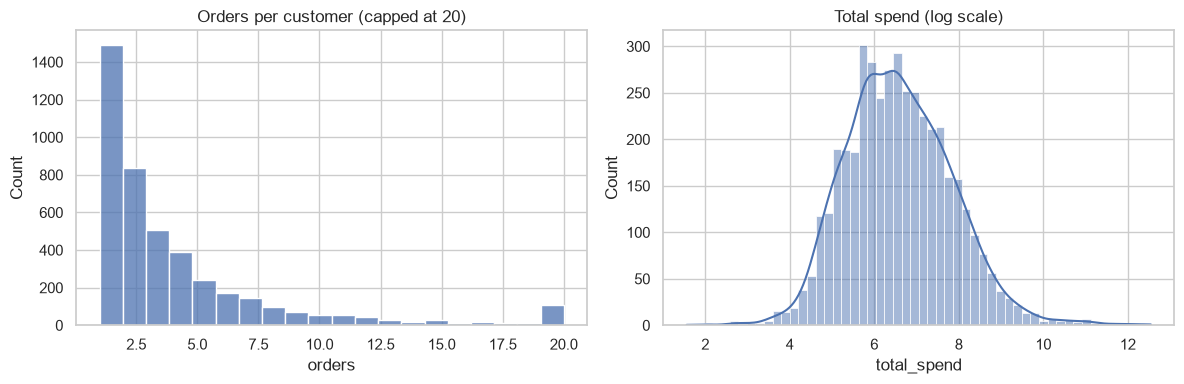

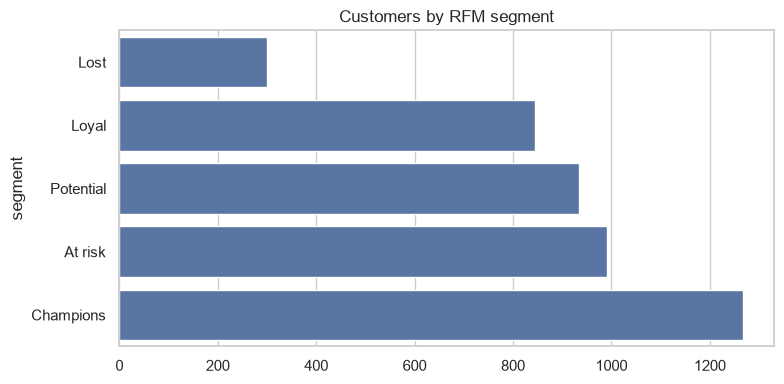

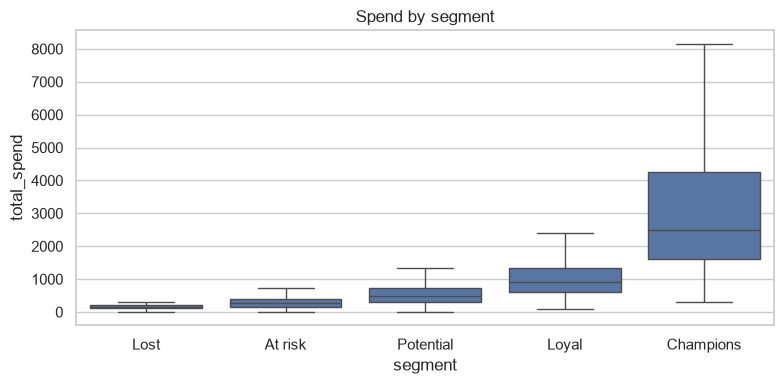

In [7]:
img = "../site/images/"

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(cust["orders"].clip(upper=20), bins=20, ax=ax[0]); ax[0].set_title("Orders per customer (capped at 20)")
sns.histplot(np.log1p(cust["total_spend"]), kde=True, ax=ax[1]); ax[1].set_title("Total spend (log scale)")
plt.tight_layout(); plt.savefig(img+"customer_distributions.png", dpi=150); plt.show()

seg = cust.groupby("segment")["CustomerID"].count().sort_values()
plt.figure(figsize=(8, 4)); sns.barplot(x=seg.values, y=seg.index)
plt.title("Customers by RFM segment"); plt.tight_layout()
plt.savefig(img+"segments.png", dpi=150); plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(data=cust, x="segment", y="total_spend", showfliers=False,
            order=["Lost","At risk","Potential","Loyal","Champions"])
plt.title("Spend by segment"); plt.tight_layout(); plt.savefig(img+"spend_by_segment.png", dpi=150); plt.show()

In [16]:
seg_counts = cust["segment"].value_counts()
data = {
  "kpis": {
    "customers": f"{n:,}",
    "repeat":    f"{repeat_rate:.1%}",
    "orders":    f"{cust['orders'].mean():.1f}",
    "churn":     f"{cust['churned'].mean():.1%}",
  },
  "findings": [
    f"{repeat_rate:.1%} of customers ordered more than once.",
    f"The top 20% of customers generate {top20:.1%} of revenue.",
    f"{cust['churned'].mean():.1%} of customers have not bought in the last 90 days of the dataset.",
    f"Champions are {seg_counts.get('Champions',0)/n:.1%} of customers; {seg_counts.get('At risk',0)/n:.1%} are at risk.",
    f"Median spend per customer is {cust['total_spend'].median():,.2f} against a mean of {cust['total_spend'].mean():,.2f}, so a small group of high spenders lifts the average.",
  ],
}
with open("../site/kpis.json", "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=2)
print(json.dumps(data, indent=2))

{
  "kpis": {
    "customers": "4,338",
    "repeat": "65.6%",
    "orders": "4.3",
    "churn": "33.4%"
  },
  "findings": [
    "65.6% of customers ordered more than once.",
    "The top 20% of customers generate 74.7% of revenue.",
    "33.4% of customers have not bought in the last 90 days of the dataset.",
    "Champions are 29.2% of customers; 22.8% are at risk.",
    "Median spend per customer is 668.57 against a mean of 2,048.69, so a small group of high spenders lifts the average."
  ]
}


In [17]:
import sqlite3, pandas as pd
con = sqlite3.connect("../data/customers.db")     

query = """
SELECT CASE WHEN orders = 1 THEN 'One-time' ELSE 'Repeat' END AS type,
       COUNT(*) AS customers, ROUND(AVG(total_spend),2) AS avg_spend
FROM customers GROUP BY 1
"""
pd.read_sql(query, con)

,type,customers,avg_spend
0,One-time,1493,411.25
1,Repeat,2845,2907.99
